# Multi-Task Training

Trains both the general classifier and personalized multi-task heads.

> Generated from `Lab2_multi_task_modal.ipynb`.

**Note:** This notebook has been converted from TensorFlow/Keras to PyTorch. All model definitions, training loops, and inference code now use PyTorch.

In [1]:
import pandas as pd
import numpy as np
import ast
import os
from sklearn.model_selection import train_test_split
from tqdm import tqdm
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import plotly.io as plt_io
import plotly.graph_objects as go
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
import plotly.express as px
import itertools
from sklearn.utils import class_weight
import random
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, roc_curve, auc, classification_report
%matplotlib inline

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cpu


True
Index(['danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness',
       'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo',
       'artist_pop', 'track_pop', 'genre_group'],
      dtype='object')
(25760, 24)
(6440, 24)
Epoch 001 | avg_loss=10.1967 (last batch: recon=8.9564, kl=0.0562)
Epoch 002 | avg_loss=7.3713 (last batch: recon=6.4685, kl=0.1615)
Epoch 003 | avg_loss=6.2319 (last batch: recon=5.8952, kl=0.1054)
Epoch 004 | avg_loss=5.8684 (last batch: recon=5.6991, kl=0.0861)
Epoch 005 | avg_loss=5.7387 (last batch: recon=5.7223, kl=0.0776)
Epoch 006 | avg_loss=5.6056 (last batch: recon=5.7134, kl=0.0590)
Epoch 007 | avg_loss=5.5381 (last batch: recon=5.3220, kl=0.0499)
Epoch 008 | avg_loss=5.4997 (last batch: recon=5.3506, kl=0.0500)
Epoch 009 | avg_loss=5.4732 (last batch: recon=5.4397, kl=0.0456)
Epoch 010 | avg_loss=5.4430 (last batch: recon=5.5569, kl=0.0433)
Epoch 011 | avg_loss=5.4148 (last batch: recon=5.5536, kl=0.0421)
Epoch 012 | avg_loss=5.

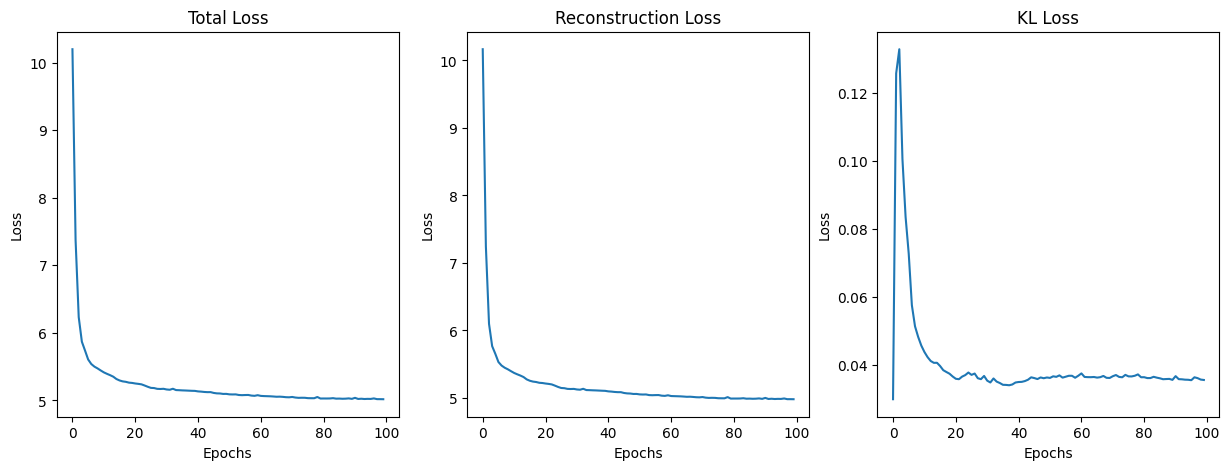

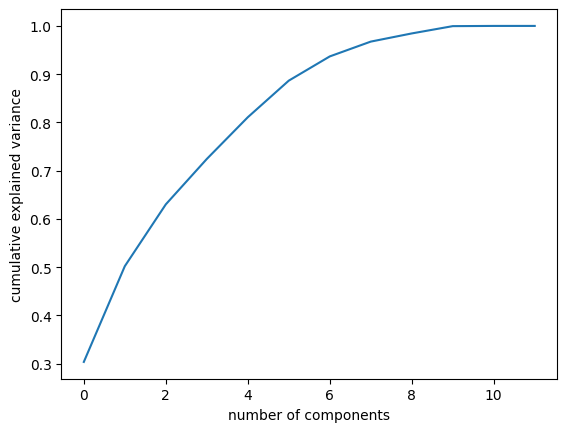

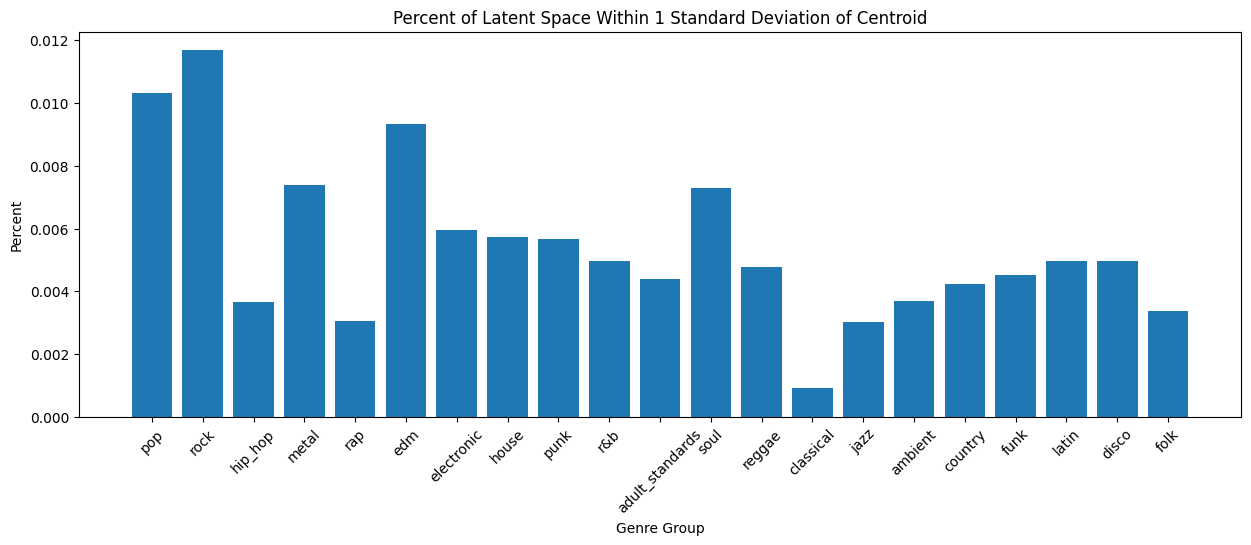

User 0 has 98.63% of songs with 0 for all three activity columns
User 1 has 98.11% of songs with 0 for all three activity columns
User 2 has 98.4% of songs with 0 for all three activity columns
X_train shape:  (61824, 13)
y_train shape:  (61824, 4)
X_test shape:  (15456, 13)
y_test shape:  (15456, 4)


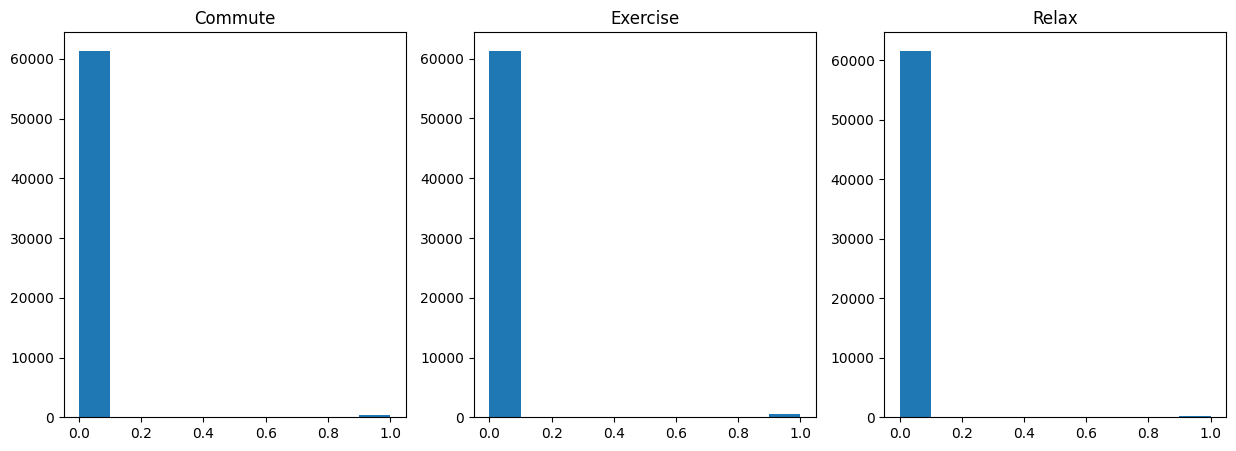

Commute:  0.007068452380952381
Exercise:  0.007699275362318841
Relax:  0.0027820910973084885


In [3]:
%run 03_encoder_inference.ipynb

In [4]:
# Define latent dimension (from encoder training)
# This should match the dimension of the encoder's latent space
latent_dim = 12


In [5]:
# Data Preparation
# Note: This assumes users_data is already defined (from encoder inference notebook)
# If not, you'll need to run the encoder inference notebook first or load users_data from a file

# Split features and targets
X = users_data.drop(columns=['exercise', 'relax', 'commute'])
y = users_data[['user', 'exercise', 'relax', 'commute']]

# Split the data into training and test sets with stratification
# Stratify by user, exercise, relax, and commute to maintain proportional representation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=users_data[['user', 'exercise', 'relax', 'commute']]
)

# Print the shape of the resulting sets
print("X_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)


X_train shape:  (61824, 13)
y_train shape:  (61824, 4)
X_test shape:  (15456, 13)
y_test shape:  (15456, 4)


# Modeling

## Architecture

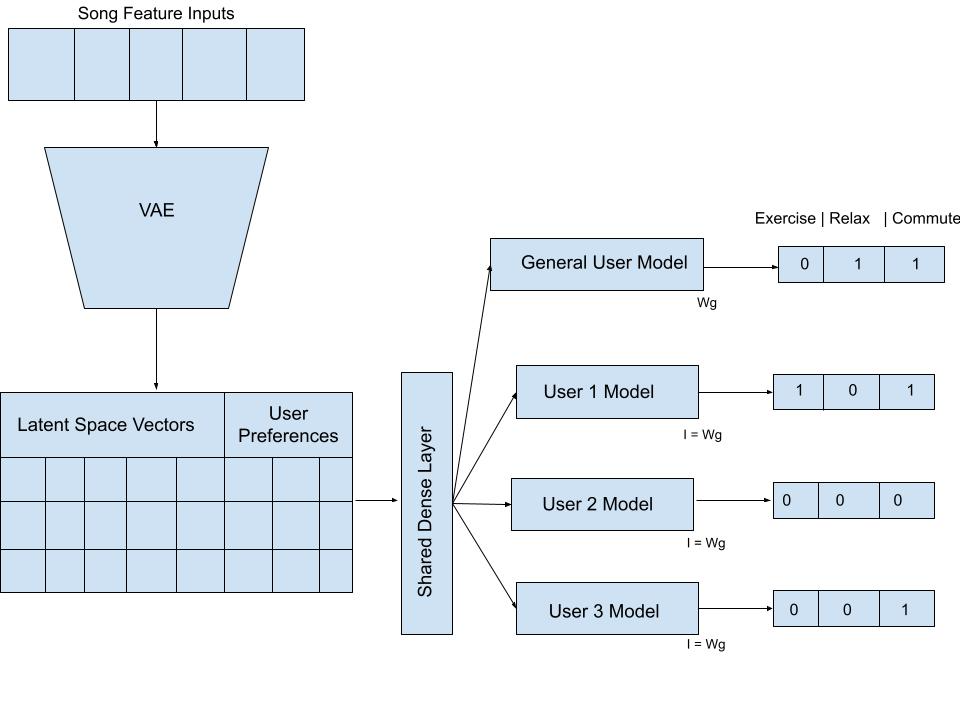

## Training a General Model

In [6]:
# Build a PyTorch model
class GeneralClassifier(nn.Module):
    def __init__(self, input_dim):
        super(GeneralClassifier, self).__init__()
        self.shared_input_layer = nn.Linear(input_dim, 12)
        self.mid_dense_9 = nn.Linear(12, 9)
        self.mid_dense_7 = nn.Linear(9, 7)
        self.output_layer = nn.Linear(7, 3)
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, x):
        x = self.relu(self.shared_input_layer(x))
        x = self.relu(self.mid_dense_9(x))
        x = self.relu(self.mid_dense_7(x))
        x = self.sigmoid(self.output_layer(x))
        return x

general_classifier = GeneralClassifier(latent_dim).to(device)
print(general_classifier) 

GeneralClassifier(
  (shared_input_layer): Linear(in_features=12, out_features=12, bias=True)
  (mid_dense_9): Linear(in_features=12, out_features=9, bias=True)
  (mid_dense_7): Linear(in_features=9, out_features=7, bias=True)
  (output_layer): Linear(in_features=7, out_features=3, bias=True)
  (relu): ReLU()
  (sigmoid): Sigmoid()
)


In [7]:
gen_X_train = X_train.drop(columns=['user'])
gen_y_train = y_train.drop(columns=['user'])
gen_X_test = X_test.drop(columns=['user'])
gen_y_test = y_test.drop(columns=['user'])

# Print the shape of the resulting sets
print("gen_X_train shape: ", gen_X_train.shape)
print("gen_y_train shape: ", gen_y_train.shape)
print("gen_X_test shape: ", gen_X_test.shape)
print("gen_y_test shape: ", gen_y_test.shape)

# Convert to PyTorch tensors
gen_X_train_tensor = torch.FloatTensor(gen_X_train.values).to(device)
gen_y_train_tensor = torch.FloatTensor(gen_y_train.values).to(device)
gen_X_test_tensor = torch.FloatTensor(gen_X_test.values).to(device)
gen_y_test_tensor = torch.FloatTensor(gen_y_test.values).to(device)

gen_X_train shape:  (61824, 12)
gen_y_train shape:  (61824, 3)
gen_X_test shape:  (15456, 12)
gen_y_test shape:  (15456, 3)


In [8]:
# Calculate class weights for reference (PyTorch uses different approach)
class_weights = {}
for i in range(3):
    class_weights[i] = {}
    for j in range(2):
        class_count = np.sum(gen_y_train.iloc[:, i] == j)
        class_weights[i][j] = class_count / len(gen_y_train.iloc[:, i])

# Training setup
optimizer = optim.Adam(general_classifier.parameters())
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

# Training loop
train_losses = []
val_losses = []
EPOCHS = 30
BATCH_SIZE = 32

for epoch in range(EPOCHS):
    general_classifier.train()
    epoch_train_loss = 0
    num_batches = 0
    
    # Training
    for i in range(0, len(gen_X_train_tensor), BATCH_SIZE):
        batch_X = gen_X_train_tensor[i:i+BATCH_SIZE]
        batch_y = gen_y_train_tensor[i:i+BATCH_SIZE]
        
        optimizer.zero_grad()
        outputs = general_classifier(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        epoch_train_loss += loss.item()
        num_batches += 1
    
    avg_train_loss = epoch_train_loss / num_batches
    train_losses.append(avg_train_loss)
    
    # Validation
    general_classifier.eval()
    with torch.no_grad():
        val_outputs = general_classifier(gen_X_test_tensor)
        val_loss = criterion(val_outputs, gen_y_test_tensor)
        val_losses.append(val_loss.item())
    
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch+1}/{EPOCHS}], Train Loss: {avg_train_loss:.4f}, Val Loss: {val_loss.item():.4f}')

print('Training completed!')

Epoch [5/30], Train Loss: 0.0251, Val Loss: 0.0238
Epoch [10/30], Train Loss: 0.0224, Val Loss: 0.0214
Epoch [15/30], Train Loss: 0.0218, Val Loss: 0.0210
Epoch [20/30], Train Loss: 0.0214, Val Loss: 0.0208
Epoch [25/30], Train Loss: 0.0212, Val Loss: 0.0207
Epoch [30/30], Train Loss: 0.0211, Val Loss: 0.0206
Training completed!


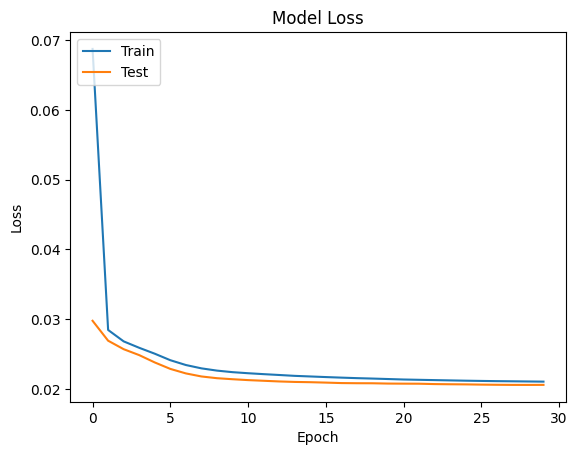

In [9]:
# Plot the loss
plt.plot(train_losses, label='Train')
plt.plot(val_losses, label='Validation')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()


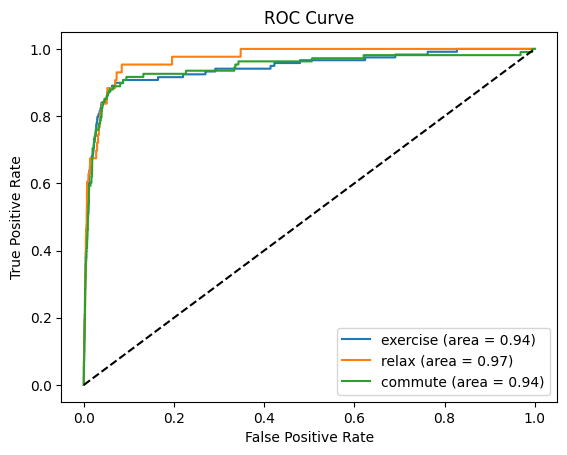

In [10]:
# Plot the AUC ROC curves for each activity
general_classifier.eval()
with torch.no_grad():
    y_pred = general_classifier(gen_X_test_tensor).cpu().numpy()

for i in range(3):
    fpr, tpr, thresholds = roc_curve(gen_y_test.iloc[:, i], y_pred[:, i])
    auc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label='{} (area = {:.2f})'.format(gen_y_test.columns[i], auc_score))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.show()


In [11]:
# Print some random example predictions
general_classifier.eval()
with torch.no_grad():
    for i in random.sample(range(len(gen_X_test)), 5):
        sample_X = torch.FloatTensor(gen_X_test.iloc[i:i+1].values).to(device)
        pred = general_classifier(sample_X).cpu().numpy()
        print('Predicted: ', pred)
        print('Actual: ', np.array(gen_y_test.iloc[i]))
        print('')
        


Predicted:  [[7.2265416e-06 3.3757371e-07 1.8520600e-06]]
Actual:  [0 0 0]

Predicted:  [[0.00269702 0.00070872 0.0048471 ]]
Actual:  [0 0 0]

Predicted:  [[1.2015925e-03 6.4859589e-05 8.8570867e-04]]
Actual:  [0 0 0]

Predicted:  [[0.01141658 0.00035    0.01043489]]
Actual:  [0 0 0]

Predicted:  [[5.598483e-04 8.885136e-05 7.974230e-04]]
Actual:  [0 0 0]



look at softmaxing the outputs

## Building a Multi Task Model

In [12]:
# Define multi-task model with shared layer
class MultiTaskModel(nn.Module):
    def __init__(self, input_dim, shared_layer=None):
        super(MultiTaskModel, self).__init__()
        # Shared input layer - reference to shared layer object
        if shared_layer is not None:
            self.shared_input_layer = shared_layer
        else:
            self.shared_input_layer = nn.Linear(input_dim, 12)
        
        # User-specific layers
        self.mid_dense_9 = nn.Linear(12, 9)
        self.mid_dense_7 = nn.Linear(9, 7)
        self.output_layer = nn.Linear(7, 3)
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, x):
        x = self.relu(self.shared_input_layer(x))
        x = self.relu(self.mid_dense_9(x))
        x = self.relu(self.mid_dense_7(x))
        x = self.sigmoid(self.output_layer(x))
        return x
    
    def get_user_specific_parameters(self):
        """Get only the user-specific parameters (excluding shared layer)"""
        return list(self.mid_dense_9.parameters()) + \
               list(self.mid_dense_7.parameters()) + \
               list(self.output_layer.parameters())

# Get the shared layer weights from the trained general classifier
shared_layer_state = general_classifier.shared_input_layer.state_dict()

# Dictionary for models for each user
user_models = {}

# Get the number of users
users = users_data['user'].unique()

# Create a single shared layer module that will be used by all models
shared_input_layer = nn.Linear(latent_dim, 12).to(device)
shared_input_layer.load_state_dict(shared_layer_state)

for user in users:
    # Create model with shared layer (all models reference the same shared_input_layer object)
    model = MultiTaskModel(latent_dim, shared_layer=shared_input_layer).to(device)
    
    # Copy weights from general classifier for user-specific layers
    model.mid_dense_9.load_state_dict(general_classifier.mid_dense_9.state_dict())
    model.mid_dense_7.load_state_dict(general_classifier.mid_dense_7.state_dict())
    model.output_layer.load_state_dict(general_classifier.output_layer.state_dict())
    
    user_models[user] = model

In [13]:
# Creating dictionaries for train and test sets whose keys are the user and values are the data
X_train_dict = dict()
y_train_dict = dict()
X_test_dict = dict()
y_test_dict = dict()

X_train_dict_df = dict()
y_train_dict_df = dict()
X_test_dict_df = dict()
y_test_dict_df = dict()

for user in y_train['user'].unique():
    X_train_dict_df[user] = X_train[y_train['user'] == user].drop(columns=['user'])
    y_train_dict_df[user] = y_train[y_train['user'] == user].drop(columns=['user'])
    X_test_dict_df[user] = X_test[y_test['user'] == user].drop(columns=['user'])
    y_test_dict_df[user] = y_test[y_test['user'] == user].drop(columns=['user'])

# Convert to PyTorch tensors
for user in y_train['user'].unique():
    X_train_dict[user] = torch.FloatTensor(X_train[y_train['user'] == user].drop(columns=['user']).values).to(device)
    y_train_dict[user] = torch.FloatTensor(y_train[y_train['user'] == user].drop(columns=['user']).values).to(device)
    X_test_dict[user] = torch.FloatTensor(X_test[y_test['user'] == user].drop(columns=['user']).values).to(device)
    y_test_dict[user] = torch.FloatTensor(y_test[y_test['user'] == user].drop(columns=['user']).values).to(device)

# Print the shape of the train and test sets
for user in users:
    print('User: ', user)
    print('X_train shape: ', X_train_dict[user].shape)
    print('y_train shape: ', y_train_dict[user].shape)
    print('X_test shape: ', X_test_dict[user].shape)
    print('y_test shape: ', y_test_dict[user].shape)
    print('')

User:  0
X_train shape:  torch.Size([20607, 12])
y_train shape:  torch.Size([20607, 3])
X_test shape:  torch.Size([5153, 12])
y_test shape:  torch.Size([5153, 3])

User:  1
X_train shape:  torch.Size([20609, 12])
y_train shape:  torch.Size([20609, 3])
X_test shape:  torch.Size([5151, 12])
y_test shape:  torch.Size([5151, 3])

User:  2
X_train shape:  torch.Size([20608, 12])
y_train shape:  torch.Size([20608, 3])
X_test shape:  torch.Size([5152, 12])
y_test shape:  torch.Size([5152, 3])



In [14]:
from random import shuffle

criterion = nn.BCELoss()

def step(key_order, opt):
    # Accumulate all the operations for the dataset
    preds = {}  # each key will be a separate user
    single_loss = {}
    
    # Set models to training mode
    for x in key_order:
        user_models[x].train()
    
    # Forward pass and backward pass for each user
    for x in key_order:
        opt[x].zero_grad()
        # Make a prediction and calculate loss for each task
        preds[x] = user_models[x](X_train_dict[x])
        loss = criterion(preds[x], y_train_dict[x])
        single_loss[x] = loss.item()
        
        # Backward pass
        loss.backward()
        opt[x].step()
    
    # Calculate overall loss
    y_all = torch.cat([y_train_dict[x] for x in users], dim=0)
    yhat_all = torch.cat([preds[x] for x in users], dim=0)
    single_loss['overall'] = criterion(yhat_all, y_all).item()
    
    return single_loss


EPOCHS = 750

# Need separate optimizers for each output task
# Note: The shared layer will be updated by all optimizers, which is fine
# Each optimizer includes the shared layer parameters
opt = {}
for x in users:
    opt[x] = optim.Adam(user_models[x].parameters())

train_losses = []
test_losses = []

for i in range(EPOCHS):
    print('Epoch', i, end=', ')
    shuffle(users)  # shuffle in place operation, maybe not needed
    
    train_losses.append(step(users, opt))  # batched gradient updates
    
    # Validation
    y_mtl = []
    yhat_mtl = []
    valid_losses = {}
    
    for x in users:
        user_models[x].eval()
        with torch.no_grad():
            # Test on data, for tracking
            yhat_mlp = user_models[x](X_test_dict[x])
            y_mtl.append(y_test_dict[x].cpu().numpy().ravel())
            yhat_mtl.append(yhat_mlp.cpu().numpy().ravel())
            
            # Calculate loss
            valid_losses[x] = criterion(yhat_mlp, y_test_dict[x]).item()
    
    # Calculate overall validation loss
    y_all_val = torch.cat([y_test_dict[x] for x in users], dim=0)
    yhat_all_val = torch.cat([user_models[x](X_test_dict[x]) for x in users], dim=0)
    with torch.no_grad():
        valid_losses['overall'] = criterion(yhat_all_val, y_all_val).item()
    
    test_losses.append(valid_losses)
    
    print('Train loss:', train_losses[-1]['overall'], 'Valid loss:', test_losses[-1]['overall'])

Epoch 0, Train loss: 0.02086849883198738 Valid loss: 0.020519180223345757
Epoch 1, Train loss: 0.020745854824781418 Valid loss: 0.02046755887567997
Epoch 2, Train loss: 0.020646270364522934 Valid loss: 0.02043232135474682
Epoch 3, Train loss: 0.02056743949651718 Valid loss: 0.020401492714881897
Epoch 4, Train loss: 0.02050543576478958 Valid loss: 0.020367931574583054
Epoch 5, Train loss: 0.020439261570572853 Valid loss: 0.02033114805817604
Epoch 6, Train loss: 0.020383238792419434 Valid loss: 0.020290622487664223
Epoch 7, Train loss: 0.02033311128616333 Valid loss: 0.02024620957672596
Epoch 8, Train loss: 0.020282916724681854 Valid loss: 0.02020060084760189
Epoch 9, Train loss: 0.020235994830727577 Valid loss: 0.020156215876340866
Epoch 10, Train loss: 0.020189553499221802 Valid loss: 0.02011384256184101
Epoch 11, Train loss: 0.020144857466220856 Valid loss: 0.020074617117643356
Epoch 12, Train loss: 0.02010958269238472 Valid loss: 0.020039038732647896
Epoch 13, Train loss: 0.020077247

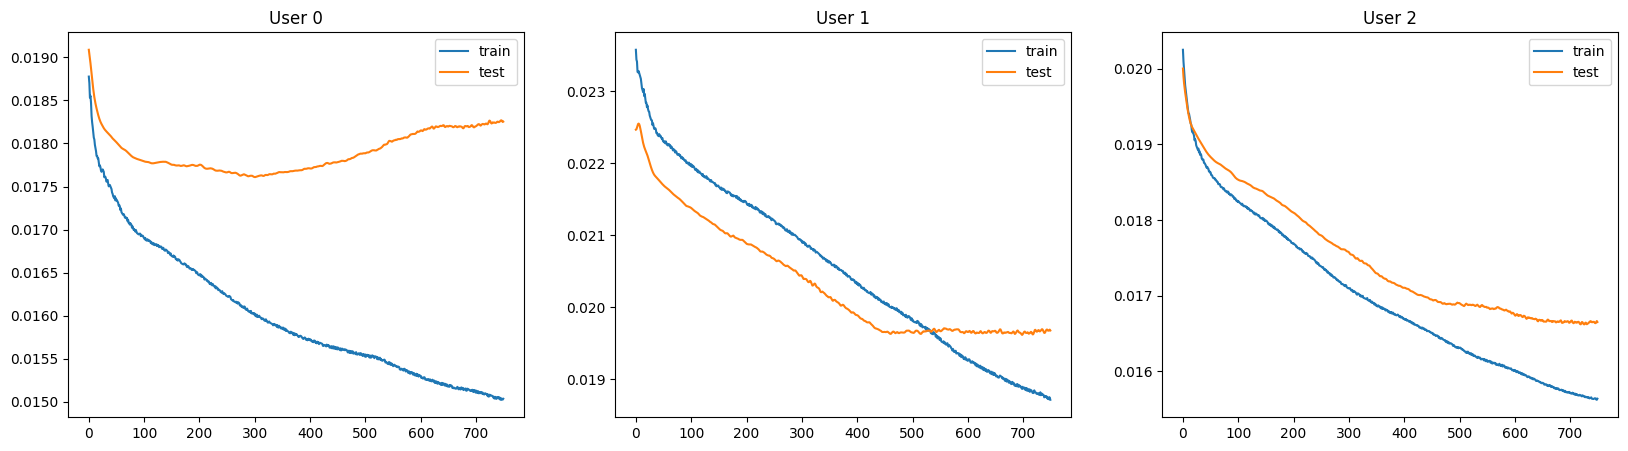

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))

for user in users:
    train_loss = [train_losses[j][user] for j in range(len(train_losses))]
    test_loss = [test_losses[j][user] for j in range(len(test_losses))]
    axs[user].plot(train_loss, label='train')
    axs[user].plot(test_loss, label='test')
    axs[user].set_title('User ' + str(user))
    axs[user].legend()

plt.show()


Both User 1 and User 2 seem to have trained to convergence while User 0 has not quite converged. This may be due to more difficult user preferences. My testing loss is also interestingly lower than my training loss.

## Model Fine-Tuning

Further training while freezing the shared layer to allow each individual model to further spcify into their own tasks without influencing the other tasks. Also initializing the learning rate lower to account for previous training and for further specificity.

In [ ]:
EPOCHS = 250

# Freeze the shared input layer (only need to do it once since all models share the same layer)
for param in shared_input_layer.parameters():
    param.requires_grad = False

# Need separate optimizers for each output task with lower learning rate
# Only optimize user-specific parameters (shared layer is frozen)
opt = {}
for x in users:
    opt[x] = optim.Adam(
        user_models[x].get_user_specific_parameters(),
        lr=1e-4
    )

train_losses = []
test_losses = []

for i in range(EPOCHS):
    print('Epoch', i, end=', ')
    shuffle(users)  # shuffle in place operation, maybe not needed
    
    train_losses.append(step(users, opt))  # batched gradient updates
    
    # Validation
    y_mtl = []
    yhat_mtl = []
    valid_losses = {}
    
    for x in users:
        user_models[x].eval()
        with torch.no_grad():
            # Test on data, for tracking
            yhat_mlp = user_models[x](X_test_dict[x])
            y_mtl.append(y_test_dict[x].cpu().numpy().ravel())
            yhat_mtl.append(yhat_mlp.cpu().numpy().ravel())
            
            # Calculate loss
            valid_losses[x] = criterion(yhat_mlp, y_test_dict[x]).item()
    
    # Calculate overall validation loss
    y_all_val = torch.cat([y_test_dict[x] for x in users], dim=0)
    yhat_all_val = torch.cat([user_models[x](X_test_dict[x]) for x in users], dim=0)
    with torch.no_grad():
        valid_losses['overall'] = criterion(yhat_all_val, y_all_val).item()
    
    test_losses.append(valid_losses)
    
    print('Train loss:', train_losses[-1]['overall'], 'Valid loss:', test_losses[-1]['overall'])

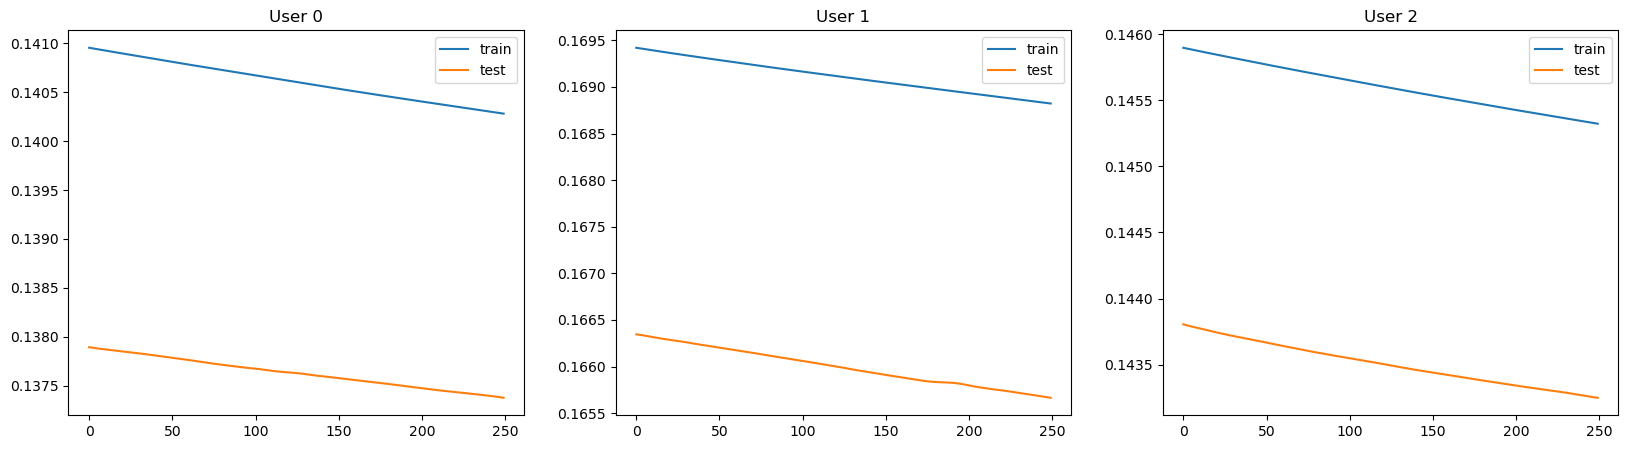

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))

for user in users:
    train_loss = [train_losses[j][user] for j in range(len(train_losses))]
    test_loss = [test_losses[j][user] for j in range(len(test_losses))]
    axs[user].plot(train_loss, label='train')
    axs[user].plot(test_loss, label='test')
    axs[user].set_title('User ' + str(user))
    axs[user].legend()

plt.show()


After fine tuning and training for 250 more epochs, the losses are steaily decreading but the differences are so small so I dont think that further training will lead to significant model improvement. This may be becuase I initialized the learning rate very low, if the learning rate was greater, the model loss may have decreased more.